In [1]:
import pandas as pd
import numpy as np
df=pd.read_csv("creditcard.csv")
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
x = df.drop(columns=["Class"])
y = df["Class"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

x_train_scaled_array = scaler.fit_transform(x_train)
x_test_scaled_array = scaler.transform(x_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(x_train_scaled_array, y_train)

logistic_predictions = logistic_model.predict(x_test_scaled_array)
print("Accuracy:", accuracy_score(y_test, logistic_predictions))

Accuracy: 0.9991397773954567


In [3]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
cm=confusion_matrix(
    y_test,logistic_predictions
)
print("confusion matrix\n:",cm)
accuracy=accuracy_score(
    y_test,logistic_predictions
)
print("Accuracy:",accuracy)
precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("Precision:", precision)
recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("Recall:", recall)
f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("F1 Score:", f1)
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

confusion matrix
: [[56851    13]
 [   36    62]]
Accuracy: 0.9991397773954567
Precision: 0.8266666666666667
Recall: 0.6326530612244898
F1 Score: 0.7167630057803468
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [4]:
print("class distribution:",df['Class'].value_counts())
print("class percentage:\n",df['Class'].value_counts(normalize=True)*100)

class distribution: Class
0    284315
1       492
Name: count, dtype: int64
class percentage:
 Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


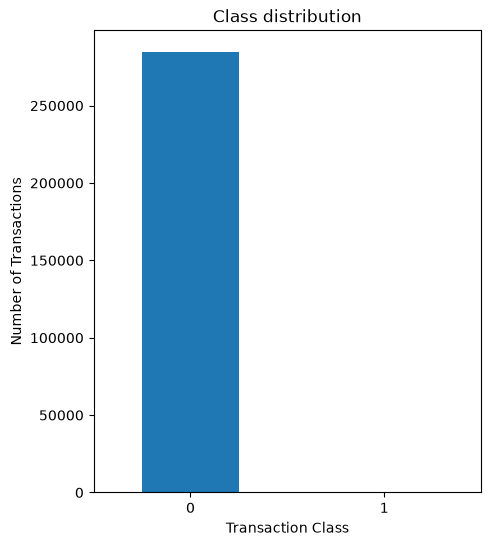

In [5]:
import matplotlib.pyplot as plt
df["Class"].value_counts().plot(
    kind="bar",
    title="Class distribution",
    figsize=(5, 6)
)
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [6]:
from sklearn.linear_model import LogisticRegression

weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_model.fit(
    x_train_scaled_array,
    y_train
)

weighted_predictions = weighted_model.predict(
    x_test_scaled_array
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, weighted_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    weighted_predictions,
    zero_division=0
))

Confusion Matrix:
[[55478  1386]
 [    8    90]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [7]:
%pip install imbalanced-learn



Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:


x_train_smote, y_train_smote = smote.fit_resample(
    x_train_scaled_array,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

NameError: name 'smote' is not defined

In [ ]:
smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model.fit(
    x_train_smote,
    y_train_smote
)

smote_predictions = smote_model.predict(
    x_test_scaled_array
)
print(classification_report(
    y_test,
    smote_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

